# 11. Chỉ số theo nhóm kênh

Tuần 2 báo cáo một con số duy nhất cho cả ba mươi bảy kênh. Con số đó che mất một cơ chế quan trọng: độ phủ của các kênh rất lệch nhau, từ khoảng chín mươi phần trăm ở nhịp tim xuống bảy phần trăm ở các xét nghiệm. Nếu neo B thật sự hoạt động qua cơ chế thay điểm tựa bằng quan sát thật, lợi ích phải tập trung ở những kênh mà hai neo khác nhau, tức là những kênh thưa.

Câu hỏi cụ thể: hiệu ứng neo đo trên từng kênh có tương quan với tỷ lệ trùng neo của chính kênh đó hay không. Đây là phép thử cơ chế trực tiếp nhất trong cả đề tài, vì nó dự đoán dấu và địa chỉ của hiệu ứng chứ không chỉ dấu.

Thiết kế: huấn luyện lại neo A và neo B với ba hạt giống, sau đó tách sai số theo từng kênh và theo ba nhóm độ phủ. Việc huấn luyện lại là bắt buộc vì các lần chạy tuần 2 chỉ lưu chỉ số tổng hợp và tổng sai số theo hồ sơ, không lưu trọng số mô hình, nên không thể tách lại theo kênh. Sổ tay này lưu trọng số ra đĩa để notebook 12 dùng lại. Chi phí ước lượng khoảng mười phút.

> **Vị trí trong chuỗi tái lập:** notebook 11 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh.
>
> **Thư mục kết quả:** `Output/processed/w3_18_chi_so_theo_nhom_kenh/`.
>
> **Mã định danh nội bộ:** `W3_18`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "w3_18_chi_so_theo_nhom_kenh"  #@param {type:"string"}
DANH_SACH_NEO = "A,B"  #@param {type:"string"}
NGUONG_TRUNG = 1e-6  #@param {type:"number"}
NGUONG_PHU_CAO = 0.50  #@param {type:"number"}
NGUONG_PHU_THAP = 0.10  #@param {type:"number"}
N_BOOT = 2000  #@param {type:"integer"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

NEO = [t.strip() for t in DANH_SACH_NEO.split(",") if t.strip()]
import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])


Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_18_chi_so_theo_nhom_kenh
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)


timestamp    2026-10-14T18:27:47
run_tag      w3_18_chi_so_theo_nhom_kenh
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")


Đã đặt quy ước trình bày hình


## 2. Mô hình, dữ liệu và hàm huấn luyện

In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


def first_observed(x, mask):
    # Trả về giá trị quan sát thật xa nhất trong cửa sổ, dùng cho phép thử đối chứng.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, Lx))
    t_star = idx.min(dim=1).values
    has = t_star < Lx
    val = torch.gather(x, 1, t_star.clamp(max=Lx - 1).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


# Tám định nghĩa neo. Z, A, B, O là neo tĩnh; C, D, E, F có cổng suy giảm học được.
# E và F giống C và D về công thức, chỉ khác điểm khởi tạo của tham số suy giảm.
NEO_HOP_LE = ("Z", "A", "B", "O", "C", "D", "E", "F")
KHOI_TAO_CONG = {"C": 0.0, "D": 0.0, "E": -6.0, "F": -6.0}


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear. Neo áp dụng cho cả hai họ, nên phép so sánh
    # Giữa hai họ và giữa các neo không bị lệch bởi nhánh mã khác nhau.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in NEO_HOP_LE, "Neo không hợp lệ: " + str(anchor)
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor in ("C", "E"):
            self.w_decay = nn.Parameter(torch.full((1,), KHOI_TAO_CONG[anchor]))
        elif anchor in ("D", "F"):
            self.w_decay = nn.Parameter(torch.full((n_channels,), KHOI_TAO_CONG[anchor]))

    def compute_anchor(self, x, mask):
        if self.anchor == "Z":
            return torch.zeros_like(x[:, -1, :])
        if self.anchor == "A":
            return x[:, -1, :]
        if self.anchor == "O":
            val_o, _ = first_observed(x, mask)
            return val_o
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        a = self.compute_anchor(x, mask)
        xr = x - a.unsqueeze(1)
        if self.kind == "nlinear":
            z = self.lin(self._flatten(xr, mask))
        else:
            trend = moving_avg(xr, self.kernel_size)
            z = self.lin_seasonal(self._flatten(xr - trend, mask)) + \
                self.lin_trend(self._flatten(trend, mask))
        return z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)


Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)


train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
# Sổ tay tuần 3 cần chính mô hình đã huấn luyện, không chỉ cần chỉ số tổng hợp,
# nên bản này giữ lại mô hình trong bộ nhớ và lưu trọng số ra đĩa.
MO_HINH_DA_HUAN_LUYEN = {}

def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True,
                      lat=None, thu_muc=None):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    lat = SPLITS if lat is None else lat
    thu_muc = RUNS if thu_muc is None else thu_muc
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in lat.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = lat["test"].tensors[2].numpy()
    my_te = lat["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + "_neo" + anchor + "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        thu_muc.mkdir(parents=True, exist_ok=True)
        (thu_muc / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(thu_muc / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(32), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    MO_HINH_DA_HUAN_LUYEN[ten] = model
    if ghi_file and kind != "persistence":
        torch.save(model.state_dict(), thu_muc / (ten + ".pt"))
    return payload


print("Đã định nghĩa hàm huấn luyện")


Đã định nghĩa hàm huấn luyện


In [7]:
def hieu_so_bat_cap(se_a, ae_a, se_b, ae_b, dem, n_boot=2000, seed=0, alpha=0.05):
    """Khoảng tin cậy cho hiệu số hai mô hình, lấy mẫu lại cùng một danh sách bệnh nhân."""
    rng = np.random.default_rng(seed)
    N = len(dem)
    d_mse, d_mae = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        d_mse[b] = (se_a[idx].sum() - se_b[idx].sum()) / mau
        d_mae[b] = (ae_a[idx].sum() - ae_b[idx].sum()) / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    mau_that = dem.sum() + EPS
    return {
        "hieu_mse": float((se_a.sum() - se_b.sum()) / mau_that),
        "hieu_mse_ci": [float(np.percentile(d_mse, lo)), float(np.percentile(d_mse, hi))],
        "hieu_mae": float((ae_a.sum() - ae_b.sum()) / mau_that),
        "hieu_mae_ci": [float(np.percentile(d_mae, lo)), float(np.percentile(d_mae, hi))],
        "p_hai_phia_mse": float(2 * min((d_mse <= 0).mean(), (d_mse >= 0).mean())),
        "p_hai_phia_mae": float(2 * min((d_mae <= 0).mean(), (d_mae >= 0).mean())),
        "mau_bootstrap_mse": d_mse,
        "mau_bootstrap_mae": d_mae,
    }


print("Đã định nghĩa hàm kiểm định bắt cặp")


Đã định nghĩa hàm kiểm định bắt cặp


In [8]:
# Đọc tổng sai số theo từng hồ sơ của nhiều tệp rồi lấy trung bình qua các hạt giống.
# Lấy trung bình trước khi bắt cặp, vì biến thiên do hạt giống không phải đối tượng cần đo.
def nap_tong_tu_danh_sach(danh_sach_tep):
    ses, aes, dem = [], [], None
    for t in danh_sach_tep:
        t = Path(t)
        assert t.exists(), "Không thấy " + str(t)
        d = np.load(t)
        if dem is None:
            dem = d["n"].astype(np.float64)
        ses.append(d["se"].astype(np.float64))
        aes.append(d["ae"].astype(np.float64))
    return np.mean(ses, axis=0), np.mean(aes, axis=0), dem


print("Đã định nghĩa hàm đọc tổng sai số theo hồ sơ")


Đã định nghĩa hàm đọc tổng sai số theo hồ sơ


In [9]:
# Một hàm dự báo duy nhất cho mọi phép phân tích chi tiết, để không có hai nhánh mã
# Khác nhau cùng tính một đại lượng.
def du_bao_tap_kiem_tra(model):
    model.eval()
    phan = []
    with torch.no_grad():
        for x, mxx, y, myy in DataLoader(SPLITS["test"], batch_size=BATCH, shuffle=False):
            phan.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    return np.concatenate(phan).astype(np.float64)


Y_TEST = SPLITS["test"].tensors[2].numpy().astype(np.float64)
M_TEST = SPLITS["test"].tensors[3].numpy().astype(np.float64)
X_TEST = SPLITS["test"].tensors[0].numpy().astype(np.float64)
MX_TEST = SPLITS["test"].tensors[1].numpy().astype(np.float64)
print("Tập kiểm tra:", Y_TEST.shape[0], "hồ sơ |", int(M_TEST.sum()), "điểm quan sát thật")


Tập kiểm tra: 1585 hồ sơ | 136752 điểm quan sát thật


## 3. Huấn luyện hai neo và lưu trọng số

Đường cơ sở Persistence được chạy trước để có mốc tham chiếu ngay trong sổ tay. Sau đó hai neo được huấn luyện với cùng số hạt giống và cùng mọi siêu tham số. Chỉ số tổng hợp in ra ở bước này phải trùng với con số của notebook 04 trong phạm vi biến thiên do hạt giống, đó là một phép tự kiểm tra miễn phí.

In [10]:
SEEDS = list(range(N_SEEDS))
t0 = time.time()
p_per = chay_mot_cau_hinh("persistence", seed=0, nhan="persistence_luoi")
MAE_PERSISTENCE = float(p_per["test"]["mae"])
MSE_PERSISTENCE = float(p_per["test"]["mse"])

TEN_MO_HINH = {neo: [] for neo in NEO}
for neo in NEO:
    for s in SEEDS:
        ten = "nlinear_neo" + neo + "_mse_s" + str(s)
        chay_mot_cau_hinh("nlinear", anchor=neo, seed=s, nhan=ten)
        TEN_MO_HINH[neo].append(ten)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")


persistence_luoi                 MSE_obs 0.5788 | MAE_obs 0.4659 | 0 giây | 0 tham số
nlinear_neoA_mse_s0              MSE_obs 0.4877 | MAE_obs 0.4709 | 11 giây | 876 tham số
nlinear_neoA_mse_s1              MSE_obs 0.4882 | MAE_obs 0.4717 | 6 giây | 876 tham số
nlinear_neoA_mse_s2              MSE_obs 0.4882 | MAE_obs 0.4725 | 7 giây | 876 tham số
nlinear_neoB_mse_s0              MSE_obs 0.4357 | MAE_obs 0.4368 | 6 giây | 876 tham số
nlinear_neoB_mse_s1              MSE_obs 0.4361 | MAE_obs 0.4372 | 9 giây | 876 tham số
nlinear_neoB_mse_s2              MSE_obs 0.4363 | MAE_obs 0.4378 | 7 giây | 876 tham số
Tổng thời gian: 0.9 phút


## 4. Độ phủ, nhóm kênh và tỷ lệ trùng neo

Độ phủ của một kênh được đo trên cửa sổ đầu vào của tập kiểm tra, không phải trên toàn bộ lưới, vì đó mới là thông tin mà neo nhìn thấy. Ba nhóm được chia theo hai ngưỡng cố định để tránh việc chọn ngưỡng theo kết quả. Tỷ lệ trùng neo là phần hồ sơ mà neo A và neo B cho cùng một giá trị, tính riêng cho từng kênh.

In [11]:
xt = torch.from_numpy(X_TEST).float()
mt = torch.from_numpy(MX_TEST).float()
neo_B, _ = last_observed(xt, mt)
neo_A = xt[:, -1, :]
trung = (neo_A - neo_B).abs().numpy() <= NGUONG_TRUNG

DO_PHU = MX_TEST.mean(axis=(0, 1))
TY_LE_TRUNG = trung.mean(axis=0)
DEM_DIEM_KENH = M_TEST.sum(axis=(0, 1))

def nhom_cua(do_phu):
    if do_phu >= NGUONG_PHU_CAO:
        return "phu_cao"
    if do_phu >= NGUONG_PHU_THAP:
        return "phu_trung_binh"
    return "phu_thap"


NHOM = {"phu_cao": [], "phu_trung_binh": [], "phu_thap": []}
for i in range(N_CH):
    NHOM[nhom_cua(float(DO_PHU[i]))].append(i)
for ten, ds in NHOM.items():
    print(ten.ljust(16), len(ds), "kênh | độ phủ trung bình",
          round(float(DO_PHU[ds].mean()) if ds else 0.0, 4),
          "| tỷ lệ trùng neo trung bình",
          round(float(TY_LE_TRUNG[ds].mean()) if ds else 0.0, 4))


phu_cao          6 kênh | độ phủ trung bình 0.6346 | tỷ lệ trùng neo trung bình 0.8304
phu_trung_binh   12 kênh | độ phủ trung bình 0.2578 | tỷ lệ trùng neo trung bình 0.496
phu_thap         19 kênh | độ phủ trung bình 0.0467 | tỷ lệ trùng neo trung bình 0.4229


## 5. Tách sai số theo kênh

Với mỗi neo, tổng sai số theo kênh được lấy trung bình qua các hạt giống trước khi chia cho số điểm, đúng quy ước đã dùng ở tuần 2. Những kênh không có điểm mục tiêu nào ở tập kiểm tra bị đánh dấu riêng và không tham gia phép tương quan.

In [12]:
def tong_theo_kenh(ten_mo_hinh):
    yhat = du_bao_tap_kiem_tra(MO_HINH_DA_HUAN_LUYEN[ten_mo_hinh])
    hieu = yhat - Y_TEST
    se = (M_TEST * hieu ** 2).sum(axis=(0, 1))
    ae = (M_TEST * np.abs(hieu)).sum(axis=(0, 1))
    return se, ae


TONG_KENH = {}
for neo in NEO:
    ses, aes = [], []
    for ten in TEN_MO_HINH[neo]:
        se, ae = tong_theo_kenh(ten)
        ses.append(se)
        aes.append(ae)
    TONG_KENH[neo] = (np.mean(ses, axis=0), np.mean(aes, axis=0))
    mse_chung = float(TONG_KENH[neo][0].sum() / (DEM_DIEM_KENH.sum() + EPS))
    print("Neo", neo, "| sai số bình phương chung tính lại từ phần tách kênh:",
          round(mse_chung, 6))


Neo A | sai số bình phương chung tính lại từ phần tách kênh: 0.488031
Neo B | sai số bình phương chung tính lại từ phần tách kênh: 0.436036


In [13]:
# Hiệu ứng neo trên từng kênh, định nghĩa là neo B trừ neo A, nên giá trị âm là có lợi.
co_diem = DEM_DIEM_KENH > 0
mse_kenh = {}
mae_kenh = {}
for neo in NEO:
    se, ae = TONG_KENH[neo]
    mse_kenh[neo] = np.where(co_diem, se / np.maximum(DEM_DIEM_KENH, 1.0), np.nan)
    mae_kenh[neo] = np.where(co_diem, ae / np.maximum(DEM_DIEM_KENH, 1.0), np.nan)

hieu_ung_kenh = mse_kenh["B"] - mse_kenh["A"]
hieu_ung_kenh_mae = mae_kenh["B"] - mae_kenh["A"]

hop_le = co_diem & np.isfinite(hieu_ung_kenh)
tq_trung = float(np.corrcoef(TY_LE_TRUNG[hop_le], hieu_ung_kenh[hop_le])[0, 1])
tq_phu = float(np.corrcoef(DO_PHU[hop_le], hieu_ung_kenh[hop_le])[0, 1])
print("Số kênh tham gia phép tương quan:", int(hop_le.sum()))
print("Tương quan giữa tỷ lệ trùng neo và hiệu ứng neo:", round(tq_trung, 5))
print("Tương quan giữa độ phủ và hiệu ứng neo     :", round(tq_phu, 5))

thu_tu = np.argsort(np.where(hop_le, hieu_ung_kenh, np.inf))
print("Năm kênh được lợi nhiều nhất:")
for i in thu_tu[:5]:
    print("   ", str(channels[i]).ljust(14), "hiệu ứng", round(float(hieu_ung_kenh[i]), 5),
          "| độ phủ", round(float(DO_PHU[i]), 4),
          "| tỷ lệ trùng neo", round(float(TY_LE_TRUNG[i]), 4))
print("Năm kênh bất lợi nhất hoặc ít lợi nhất:")
for i in [j for j in thu_tu if hop_le[j]][-5:]:
    print("   ", str(channels[i]).ljust(14), "hiệu ứng", round(float(hieu_ung_kenh[i]), 5),
          "| độ phủ", round(float(DO_PHU[i]), 4),
          "| tỷ lệ trùng neo", round(float(TY_LE_TRUNG[i]), 4))


Số kênh tham gia phép tương quan: 35
Tương quan giữa tỷ lệ trùng neo và hiệu ứng neo: 0.39962
Tương quan giữa độ phủ và hiệu ứng neo     : 0.57016
Năm kênh được lợi nhiều nhất:
    Bilirubin      hiệu ứng -0.7941 | độ phủ 0.0194 | tỷ lệ trùng neo 0.6107
    BUN            hiệu ứng -0.55198 | độ phủ 0.0785 | tỷ lệ trùng neo 0.0934
    Creatinine     hiệu ứng -0.53154 | độ phủ 0.0789 | tỷ lệ trùng neo 0.094
    Lactate        hiệu ứng -0.48425 | độ phủ 0.0514 | tỷ lệ trùng neo 0.4927
    SaO2           hiệu ứng -0.48042 | độ phủ 0.0458 | tỷ lệ trùng neo 0.6107
Năm kênh bất lợi nhất hoặc ít lợi nhất:
    RespRate       hiệu ứng 0.00781 | độ phủ 0.2479 | tỷ lệ trùng neo 0.9703
    Cholesterol    hiệu ứng 0.00807 | độ phủ 0.0021 | tỷ lệ trùng neo 0.9249
    NISysABP       hiệu ứng 0.00825 | độ phủ 0.4279 | tỷ lệ trùng neo 0.5672
    NIDiasABP      hiệu ứng 0.00946 | độ phủ 0.4272 | tỷ lệ trùng neo 0.571
    NIMAP          hiệu ứng 0.01512 | độ phủ 0.4221 | tỷ lệ trùng neo 0.5647


## 6. Kiểm định bắt cặp theo nhóm kênh

Hiệu số của từng nhóm được kèm khoảng tin cậy lấy mẫu lặp ở cấp bệnh nhân, vì các điểm trong cùng một hồ sơ không độc lập. Lưu ý mẫu số ở đây là số điểm của riêng nhóm, không phải tổng số điểm, nên các hiệu số giữa các nhóm không cộng lại thành hiệu số chung.

In [14]:
def tong_theo_ho_so_nhom(ten_mo_hinh, cot):
    yhat = du_bao_tap_kiem_tra(MO_HINH_DA_HUAN_LUYEN[ten_mo_hinh])
    hieu = (yhat - Y_TEST)[:, :, cot]
    m = M_TEST[:, :, cot]
    se = (m * hieu ** 2).sum(axis=(1, 2))
    ae = (m * np.abs(hieu)).sum(axis=(1, 2))
    dem = m.sum(axis=(1, 2))
    return se, ae, dem


KIEM_DINH_NHOM = {}
for ten_nhom, cot in NHOM.items():
    if not cot:
        print("Nhóm", ten_nhom, "không có kênh nào, bỏ qua")
        continue
    goi = {}
    for neo in NEO:
        ses, aes, dem = [], [], None
        for ten in TEN_MO_HINH[neo]:
            se, ae, d = tong_theo_ho_so_nhom(ten, cot)
            ses.append(se)
            aes.append(ae)
            dem = d
        goi[neo] = (np.mean(ses, axis=0), np.mean(aes, axis=0), dem)
    kq = hieu_so_bat_cap(goi["B"][0], goi["B"][1], goi["A"][0], goi["A"][1],
                         goi["A"][2], n_boot=N_BOOT, seed=0)
    KIEM_DINH_NHOM[ten_nhom] = {
        "so_kenh": len(cot),
        "so_diem": float(goi["A"][2].sum()),
        "mse_neoA": float(goi["A"][0].sum() / (goi["A"][2].sum() + EPS)),
        "mse_neoB": float(goi["B"][0].sum() / (goi["B"][2].sum() + EPS)),
        "hieu_mse": kq["hieu_mse"], "hieu_mse_ci": kq["hieu_mse_ci"],
        "p_mse": kq["p_hai_phia_mse"],
        "hieu_mae": kq["hieu_mae"], "hieu_mae_ci": kq["hieu_mae_ci"],
        "p_mae": kq["p_hai_phia_mae"],
        "ty_le_trung_neo_trung_binh": float(TY_LE_TRUNG[cot].mean()),
        "do_phu_trung_binh": float(DO_PHU[cot].mean()),
    }
    print(ten_nhom.ljust(16), "hiệu MSE", round(kq["hieu_mse"], 6),
          kq["hieu_mse_ci"], "p", round(kq["p_hai_phia_mse"], 4))


phu_cao          hiệu MSE -0.013374 [-0.01865934553401235, -0.008289351069586308] p 0.0
phu_trung_binh   hiệu MSE -0.045351 [-0.0570289771804703, -0.03065035592041548] p 0.0
phu_thap         hiệu MSE -0.317032 [-0.36586703870966775, -0.2733972099696337] p 0.0


## 7. Hai hình chính

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_18_chi_so_theo_nhom_kenh/figures/W3_18_chi_so_theo_nhom_kenh.png


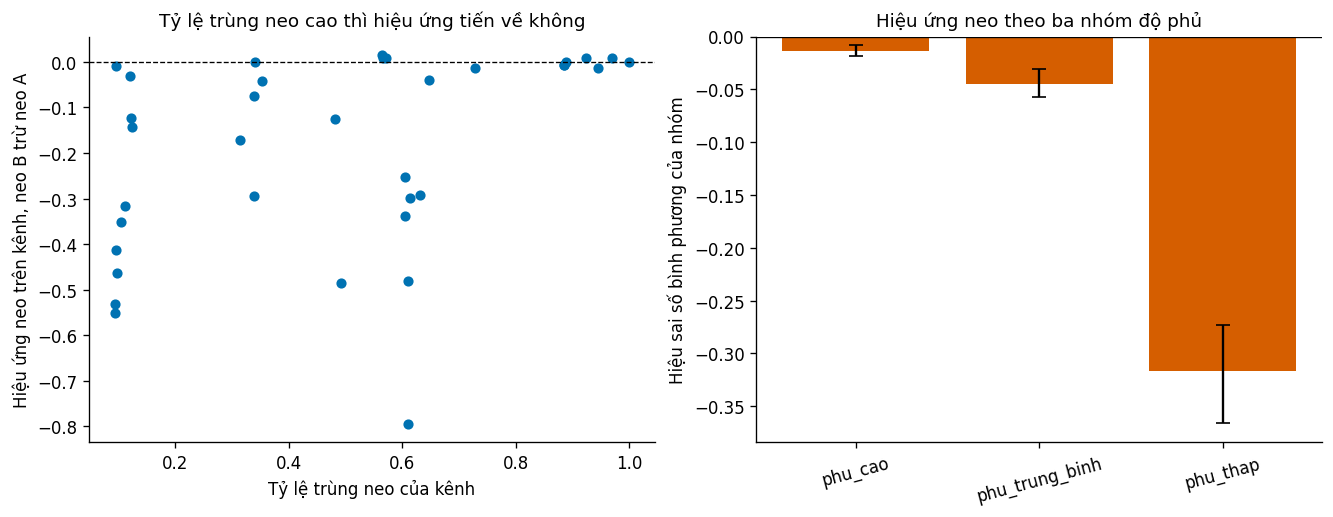

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11.0, 4.2))
ax[0].scatter(TY_LE_TRUNG[hop_le], hieu_ung_kenh[hop_le], s=26, color=PALETTE[0])
ax[0].axhline(0.0, color="black", linewidth=0.8, linestyle="--")
ax[0].set_xlabel("Tỷ lệ trùng neo của kênh")
ax[0].set_ylabel("Hiệu ứng neo trên kênh, neo B trừ neo A")
ax[0].set_title("Tỷ lệ trùng neo cao thì hiệu ứng tiến về không")

ten_nhom = [t for t in ("phu_cao", "phu_trung_binh", "phu_thap") if t in KIEM_DINH_NHOM]
gia = [KIEM_DINH_NHOM[t]["hieu_mse"] for t in ten_nhom]
ci = [KIEM_DINH_NHOM[t]["hieu_mse_ci"] for t in ten_nhom]
duoi = [g - x[0] for g, x in zip(gia, ci)]
tren = [x[1] - g for g, x in zip(gia, ci)]
ax[1].bar(ten_nhom, gia, yerr=[duoi, tren], color=PALETTE[1], capsize=4)
ax[1].axhline(0.0, color="black", linewidth=0.8)
ax[1].set_ylabel("Hiệu sai số bình phương của nhóm")
ax[1].set_title("Hiệu ứng neo theo ba nhóm độ phủ")
ax[1].tick_params(axis="x", rotation=15)
luu_hinh(fig, "W3_18_chi_so_theo_nhom_kenh.png")
plt.show()


## 8. Ghi kết quả

In [16]:
bang_kenh = []
for i in range(N_CH):
    bang_kenh.append({
        "kenh": str(channels[i]),
        "do_phu": float(DO_PHU[i]),
        "ty_le_trung_neo": float(TY_LE_TRUNG[i]),
        "so_diem_muc_tieu": float(DEM_DIEM_KENH[i]),
        "mse_neoA": None if not co_diem[i] else float(mse_kenh["A"][i]),
        "mse_neoB": None if not co_diem[i] else float(mse_kenh["B"][i]),
        "hieu_ung_mse": None if not co_diem[i] else float(hieu_ung_kenh[i]),
        "hieu_ung_mae": None if not co_diem[i] else float(hieu_ung_kenh_mae[i]),
        "nhom": nhom_cua(float(DO_PHU[i])),
    })

ket_qua = {
    "kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG, "read_tag": READ_TAG, "n_seeds": N_SEEDS,
    "n_boot": N_BOOT, "nguong_trung": NGUONG_TRUNG,
    "nguong_phu_cao": NGUONG_PHU_CAO, "nguong_phu_thap": NGUONG_PHU_THAP,
    "mse_persistence": MSE_PERSISTENCE, "mae_persistence": MAE_PERSISTENCE,
    "tuong_quan_ty_le_trung_va_hieu_ung": tq_trung,
    "tuong_quan_do_phu_va_hieu_ung": tq_phu,
    "kiem_dinh_nhom": KIEM_DINH_NHOM,
    "bang_kenh": bang_kenh,
}
dich = RUN_DIR / "W3_chi_so_theo_nhom_kenh.json"
dich.write_text(json.dumps(ket_qua, ensure_ascii=False, indent=2))
print("Đã ghi", dich)
print("Trọng số mô hình đã lưu trong", RUNS)


Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_18_chi_so_theo_nhom_kenh/W3_chi_so_theo_nhom_kenh.json
Trọng số mô hình đã lưu trong /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/w3_18_chi_so_theo_nhom_kenh/runs
